# Phase 3 – Basic analyses: the general picture

This notebook answers the coach's first request: how did the WRFT teams and dogs do in 2023 on **start times, run times, passes (changeovers) and faults**, compared with the teams they raced? It also defines what a **"good result"** is, because the brief leaves that to the analyst.

The logic lives in `src/flyball/metrics.py` (tables), `src/flyball/stats.py` (models) and `src/flyball/plots/phase3.py` (draft charts). `scripts/run_phase3_basic.py` rebuilds all the tables in `reports/phase3/` and the figures in `figures/phase3/`. Every choice is recorded in `ANALYSIS_LOG.md`, Step 2.

**Ground rules** (from the cleaning phase):
- Practice rows are dropped.
- Speed uses only clean, plausible runs (`valid_speed`); start and pass times use `valid_pass`.
- Divisions are numbered per competition, so a team's **peers** are the teams of the same *competition × division*.
- Ties count as half a win.

In [1]:
import pandas as pd
from IPython.display import display
from flyball import metrics, stats
from flyball.plots import phase3 as plots, style

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
style.apply()

t = metrics.load_processed()
heats, runs, dogs = t["heats"], t["runs"], t["dogs"]
view = metrics.heat_view(heats)
print(f"{len(heats):,} team rows ({heats['is_wrft'].sum():,} WRFT), {len(runs):,} dog slots, "
      f"{len(view) // 2:,} paired heats")

8,543 team rows (1,123 WRFT), 33,865 dog slots, 4,226 paired heats


## 1. What is a "good result"? What wins a heat?

A race is a series of heats, and the heat is the unit a team can influence. Two things can decide a heat:
- **speed**: the faster team wins, if both run clean;
- **faults**: a false start, an early pass or a run fault (missed hurdle, ran in) must be re-run, which costs seconds, or left uncorrected, which loses the heat.

First, the plain win rates, seen from every team in every heat:

,own,opp,team_heats,win_rate,ci_low,ci_high
0,own clean,opponent clean,3532,0.493,0.476,0.509
1,own clean,opponent fault,1944,0.850,0.833,0.865
2,own fault,opponent clean,1944,0.089,0.077,0.102
3,own fault,opponent fault,956,0.191,0.168,0.218


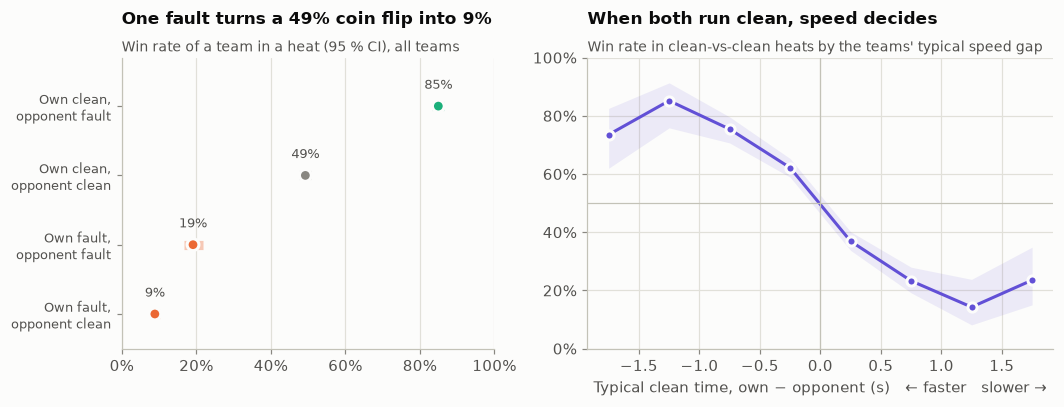

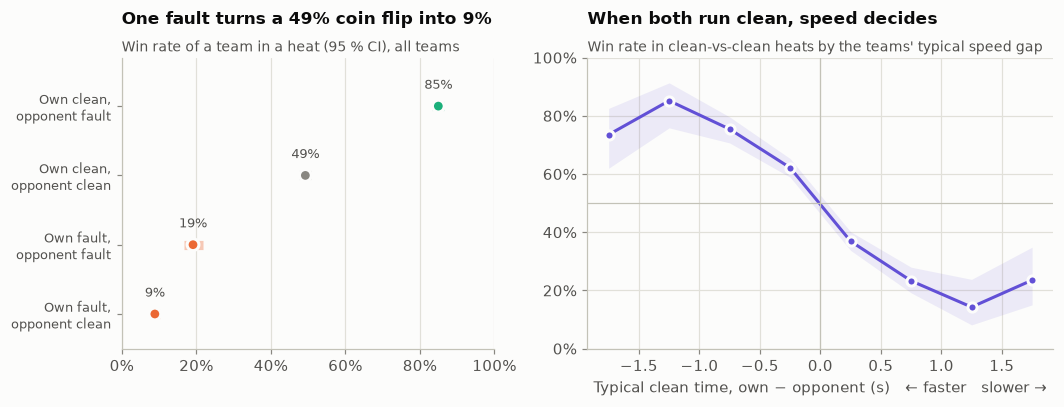

In [2]:
by_fault = metrics.win_by_fault_status(view)
by_gap = metrics.win_by_speed_gap(view)
display(by_fault)
plots.what_wins(by_fault, by_gap)

**Reading it:** when both teams run clean, a heat is a coin flip (49 %). If only our team faults, we win **9 %** of the time. If only the opponent faults, we win 85 %. When both run clean, speed decides: a team that is typically up to 0.5 s faster wins 62 % of those heats, and one up to 0.5 s slower wins 37 %.

To weigh the two directly, a logistic model predicts the heat result from:
- the **typical** speed and start of each team that day (median clean time and median start in the team's *other* heats, so the heat's own result does not leak in);
- which faults each side made in this heat.

Standard errors are clustered on race. Three versions are compared: speed only, faults only, and both.

In [3]:
models = {"field": stats.heat_win_models(metrics.heat_model_frame(view)),
          "WRFT": stats.heat_win_models(metrics.heat_model_frame(view, wrft_focal=True))}
display(pd.concat([m["comparison"].assign(sample=k) for k, m in models.items()]))
display(pd.concat([stats.coef_table(m["fits"]["full"], exp=True).assign(sample=k)
                   for k, m in models.items()]))

,model,n_heats,pseudo_r2,auc,sample
0,speed,4146,0.017,0.603,field
1,faults,4146,0.249,0.807,field
2,full,4146,0.266,0.841,field
0,speed,1000,0.035,0.645,WRFT
1,faults,1000,0.218,0.796,WRFT
2,full,1000,0.258,0.839,WRFT


,term,estimate,ci_low,ci_high,p_value,sample
0,Intercept,1.010,0.916,1.113,8.468e-01,field
1,speed_gap,0.655,0.577,0.743,5.216e-11,field
2,start_gap,0.479,0.150,1.530,2.143e-01,field
3,own_false_start,0.069,0.044,0.107,8.885e-33,field
4,own_pass_fault,0.061,0.046,0.082,1.039e-80,field
5,own_run_fault,0.305,0.212,0.438,1.244e-10,field
6,opp_false_start,3.130,2.408,4.069,1.503e-17,field
7,opp_pass_fault,4.059,3.314,4.972,9.234e-42,field
8,opp_run_fault,3.755,2.565,5.496,9.969e-12,field
0,Intercept,1.023,0.838,1.250,8.213e-01,WRFT


**Faults explain far more than speed.**
- Who faulted explains about 15 times more of the heat results than the typical speed gap: pseudo-R² 0.25 vs 0.02 for the whole field, and 0.22 vs 0.04 for WRFT. Speed only adds a little on top.
- A false start or an early pass cuts the odds of winning to about **one fifteenth** (OR 0.06–0.07), and to about 1/8–1/13 per fault type for WRFT.
- Each second of typical-speed advantage multiplies the odds by about 1.5 (OR 0.66 per second slower).
- The typical start gap adds nothing once speed and faults are in the model.

**Definition used from here on.** A good result is a **won heat**. The two levers behind it are, in order of weight:
1. a **clean heat** (no start, pass or run fault);
2. a **faster clean time** than the division peers.

> **For the coach:** cutting faults is worth more than shaving tenths. A clean heat at normal speed wins about half the time; a heat with a fault almost never wins.

## 2. Why WRFT loses heats

Every decided team row gets a reason:
- won clean / won despite a corrected fault;
- lost with its own coded fault;
- lost with rerun time but no coded fault (for example a dropped ball, which is not coded in the sheets);
- lost clean but slower;
- lost clean while the opponent also lost (a likely break-out);
- lost with not all dogs finishing.

A faulted loss is marked **avoidable** when the team's typical clean total that day (median of its other clean heats) would have beaten the opponent's actual winning total.

reason,group,heats,win_clean,win_after_fault,loss_fault,loss_uncoded_rerun,loss_slower,loss_breakout_like,loss_not_finished,losses,avoidable_losses,share_losses_with_fault,share_losses_avoidable
0,Field (non-WRFT),7338,2880,467,2187,248,1262,97,197,3991,950,0.610,0.238
1,WildRunners Maximini,228,79,11,85,10,38,2,3,138,31,0.688,0.225
2,WildRunners Nightfall,153,65,17,40,5,26,0,0,71,21,0.634,0.296
3,WildRunners Wonders,44,7,4,17,3,8,0,5,33,7,0.606,0.212
4,WildRunners XXL,115,25,12,45,6,23,3,1,78,5,0.654,0.064
5,WildRunners Zephyr,213,69,17,72,5,42,6,2,127,38,0.606,0.299
6,WildRunners dreamers,174,64,9,49,2,44,4,2,101,19,0.505,0.188
7,WildRunners hopefuls,187,67,8,68,3,39,1,1,112,34,0.634,0.304
8,WRFT (all teams),1114,376,78,376,34,220,16,14,660,155,0.621,0.235


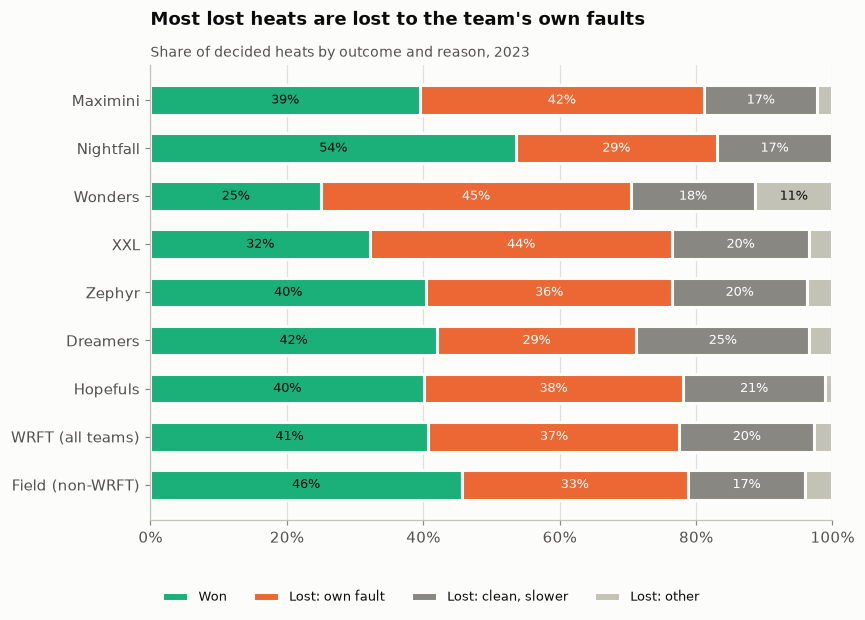

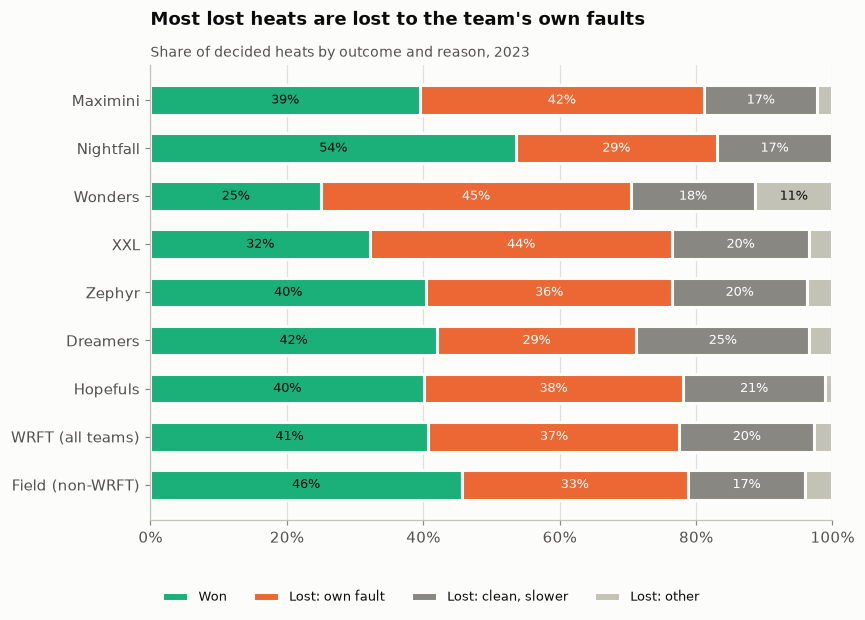

In [4]:
attr = metrics.fault_attribution(heats)
attr["group"] = attr["team"].where(attr["is_wrft"], "Field (non-WRFT)")
summary = pd.concat([metrics.attribution_summary(attr, ["group"]),
                     metrics.attribution_summary(attr[attr["is_wrft"]].assign(group="WRFT (all teams)"), ["group"])],
                    ignore_index=True)
display(summary)
order = [*sorted(g for g in summary["group"] if g.startswith("WildRunners")), "WRFT (all teams)", "Field (non-WRFT)"]
fa = summary.set_index("group").loc[order].reset_index()
plots.heat_outcomes(fa.assign(label=fa["group"].map(plots.short_team)), "label")

In [5]:
wrft_avoidable = attr[attr["is_wrft"] & attr["avoidable"]]
print("Avoidable WRFT losses by fault type (a heat can have more than one):")
print({k: int(wrft_avoidable[k].sum()) for k in ["any_false_start", "any_pass_fault", "any_run_fault"]})
display(metrics.fault_cost_seconds(heats))

Avoidable WRFT losses by fault type (a heat can have more than one):
{'any_false_start': 58, 'any_pass_fault': 99, 'any_run_fault': 20}


,fault,team_heats,loss_rate,corrected_n,rerun_seconds_median
0,false_start,637,0.862,141,7.76
1,pass_fault,1369,0.888,79,8.33
2,run_fault,316,0.693,0,NaN
3,none,4752,0.336,0,NaN


**Reading it:**
- **62 %** of WRFT's 660 lost heats were lost with a fault of their own.
- **155 lost heats (23 % of all losses) were avoidable:** WRFT's usual clean time that day would have beaten the opponent's winning time.
  - Early passes appear in 99 of them, false starts in 58 and run faults in 20.
- One fault loses the heat 86–89 % of the time, against 34 % for clean heats.
- When a false start or early pass is corrected, the rerun adds about **8 s** to the total (median 7.8 s and 8.3 s). That is roughly two dogs' worth of time, so a corrected fault usually still loses.
- Run faults have no measurable rerun cost, because the faulted run has no time in the sheet.

> **For the coach:** about 155 heats in 2023 were lost with a faster team on the line. Early passes are the biggest single source, then false starts.

## 3. Teams against their division peers

Raw team numbers mix very different competitions and divisions. The fair comparison is each WRFT team against the **other teams in the same competition × division**: a regression with division fixed effects and standard errors clustered on team. Differences are team − peers. For rates, 0.05 means 5 percentage points. p-values are Holm-adjusted over all 42 tests (7 teams × 6 metrics).

In [6]:
wrft = heats["is_wrft"]
display(metrics.team_summary(heats[wrft], runs[runs["is_wrft"]], ["team"]).set_index("team").T)

team,WildRunners Maximini,WildRunners Nightfall,WildRunners Wonders,WildRunners XXL,WildRunners Zephyr,WildRunners dreamers,WildRunners hopefuls
heats,228.000,153.000,44.000,115.000,214.000,174.000,188.000
win_rate,0.395,0.536,0.250,0.322,0.404,0.420,0.402
clean_heat_rate,0.500,0.595,0.341,0.435,0.547,0.644,0.574
median_clean_time,17.440,17.360,21.590,21.300,18.580,16.590,16.090
best_clean_time,16.160,16.400,17.910,18.810,16.020,15.520,15.610
false_start_rate,0.136,0.150,0.159,0.322,0.145,0.149,0.112
heat_pass_fault_rate,0.272,0.229,0.205,0.217,0.210,0.195,0.309
heat_run_fault_rate,0.048,0.059,0.114,0.070,0.136,0.029,0.016
rerun_seconds_per_heat,1.282,1.125,3.523,2.607,1.505,0.612,0.951
win_ci_low,0.334,0.457,0.146,0.243,0.341,0.349,0.334


metric,clean_heat_rate,clean_time_s,false_start_rate,pass_fault_rate,run_fault_rate,win_rate
team,,,,,,
WildRunners Maximini,-0.076,0.400,0.020,0.042,0.002,-0.073
WildRunners Nightfall,0.007,-0.416,0.055,-0.003,0.020,0.093
WildRunners Wonders,-0.202,2.203,0.008,0.061,0.050,-0.244
WildRunners XXL,-0.102,2.429,0.200,0.020,0.009,-0.150
WildRunners Zephyr,-0.020,0.080,0.042,0.019,0.079,-0.066
WildRunners dreamers,0.090,-0.091,0.037,-0.041,-0.024,-0.047
WildRunners hopefuls,-0.015,-0.039,0.030,0.058,-0.006,-0.065


,team,metric,estimate,ci_low,ci_high,p_value,n,p_holm
0,WildRunners Maximini,clean_time_s,0.400,0.235,0.566,2.086e-06,1339,7.718e-05
1,WildRunners Maximini,win_rate,-0.073,-0.110,-0.037,8.091e-05,1422,2.670e-03
2,WildRunners Maximini,clean_heat_rate,-0.076,-0.112,-0.040,3.866e-05,1422,1.315e-03
6,WildRunners Nightfall,clean_time_s,-0.416,-0.674,-0.158,1.550e-03,808,3.875e-02
7,WildRunners Nightfall,win_rate,0.093,0.041,0.146,4.789e-04,853,1.389e-02
9,WildRunners Nightfall,false_start_rate,0.055,0.021,0.088,1.379e-03,853,3.661e-02
12,WildRunners Wonders,clean_time_s,2.203,1.837,2.569,4.407e-32,255,1.851e-30
13,WildRunners Wonders,win_rate,-0.244,-0.340,-0.148,6.489e-07,277,2.466e-05
14,WildRunners Wonders,clean_heat_rate,-0.202,-0.285,-0.118,2.220e-06,277,7.992e-05
17,WildRunners Wonders,run_fault_rate,0.050,0.018,0.081,2.068e-03,277,4.963e-02


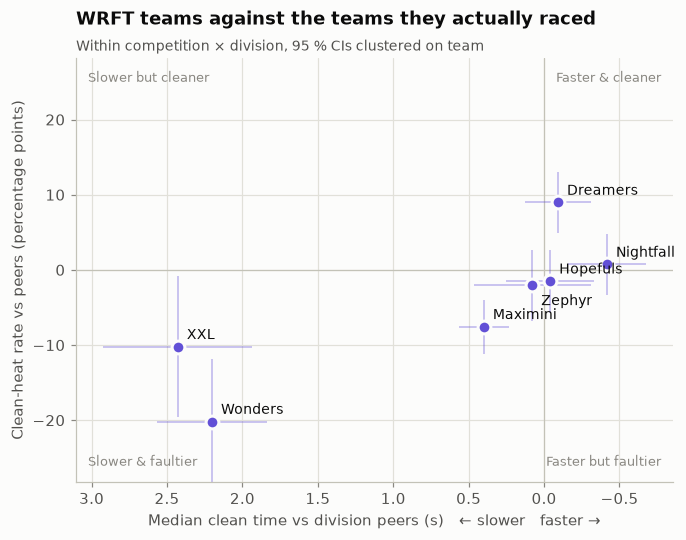

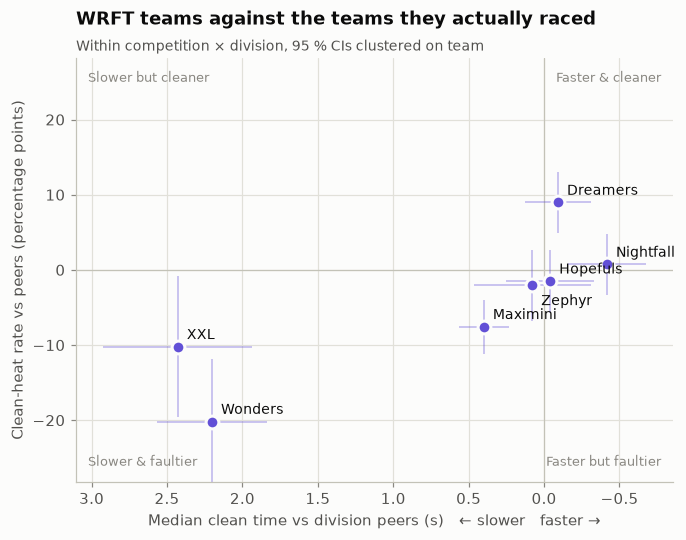

In [7]:
peer = metrics.peer_benchmark(heats)
display(peer.pivot(index="team", columns="metric", values="estimate").round(3))
display(peer[peer["p_holm"] < 0.05])
plots.team_quadrant(peer)

In [8]:
ranks = metrics.division_ranks(heats)
display(ranks.groupby("team").agg(divisions=("comp_div", "size"),
                                  ranked_first=("rank", lambda s: int((s == 1).sum())),
                                  median_gap_s=("gap_to_div_median", "median")))

,divisions,ranked_first,median_gap_s
team,,,
WildRunners Maximini,10,2,0.187
WildRunners Nightfall,7,3,-0.130
WildRunners Wonders,2,0,2.147
WildRunners XXL,5,0,1.960
WildRunners Zephyr,10,1,0.190
WildRunners dreamers,9,1,-0.020
WildRunners hopefuls,8,1,0.055


**Reading it:**
- **Nightfall** is the best WRFT team. It is 0.42 s faster than its peers and wins 9 points more often, but it has 5.5 points more false starts.
- **Dreamers** is the cleanest team: +9 points clean heats, and fewer run faults than its peers.
- **Hopefuls** has peer-level speed but too many early passes (+5.8 points) and false starts (+3 points).
- **Maximini** is 0.40 s slower than its peers, with 7.6 points fewer clean heats.
- **XXL** has a false-start rate **20 points above** its peers.
- **Zephyr** has 8 points more run faults than its peers.
- **Wonders** and **XXL** are about 2.2–2.4 s slower than their divisions, so they are placed in divisions above their speed.

> **For the coach:** each team has one clear fix. XXL: the start. Hopefuls: the passes. Zephyr: run faults. Wonders and XXL should be entered in slower divisions (seeding).

## 4. Starts and passes: tight vs risky

**A note on the `ok` pass code.** Numeric passes between 0.00 and 0.07 s almost never appear (19 values), yet `ok` is 34 % of all passes. `ok` is also more common for dogs whose numeric passes are tight. So `ok` is a **censored value**: a tight pass below about 0.08 s whose exact time the display does not show. Medians are still correct with `ok` = 0, because it is the smallest value. Means use 0.04 s, the middle of the range.

The trade-off is measured between dogs. Every dog in the field with at least 20 attempts is grouped by its **median** start or pass time, and the fault rate is compared across groups. An expected cost per attempt = average time on the line + fault rate × rerun cost (from section 2) puts both in seconds.

,bin,kind,dogs,attempts,faults,median_time_s,mean_time_s,fault_rate,fault_ci_low,fault_ci_high,expected_cost_s,is_window
0,"(0.0, 0.05]",start,3,67,8,0.050,0.057,0.119,0.062,0.218,0.983,False
1,"(0.05, 0.08]",start,39,2386,198,0.070,0.078,0.083,0.073,0.095,0.722,True
2,"(0.08, 0.11]",start,39,2062,230,0.100,0.112,0.112,0.099,0.126,0.978,False
3,"(0.11, 0.14]",start,23,1315,143,0.130,0.139,0.109,0.093,0.127,0.983,False
4,"(0.14, 0.18]",start,14,605,95,0.170,0.177,0.157,0.130,0.188,1.396,False
5,"(0.18, 0.25]",start,2,67,9,0.225,0.341,0.134,0.072,0.236,1.383,False
6,"(-inf, 0.08]",pass,68,4666,509,0.000,0.124,0.109,0.100,0.118,1.032,False
7,"(0.08, 0.12]",pass,31,2244,236,0.110,0.144,0.105,0.093,0.119,1.020,False
8,"(0.12, 0.16]",pass,90,5932,526,0.145,0.172,0.089,0.082,0.096,0.911,False
9,"(0.16, 0.2]",pass,64,3376,311,0.180,0.222,0.092,0.083,0.102,0.989,False


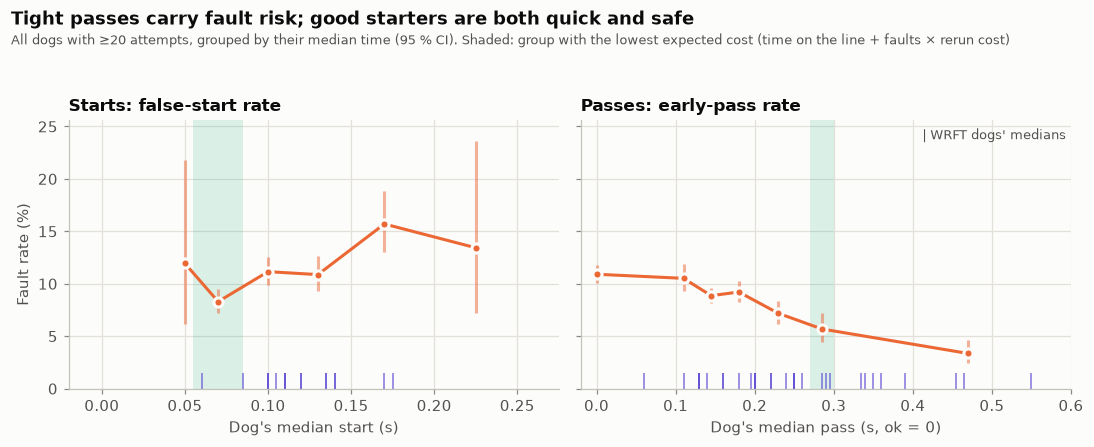

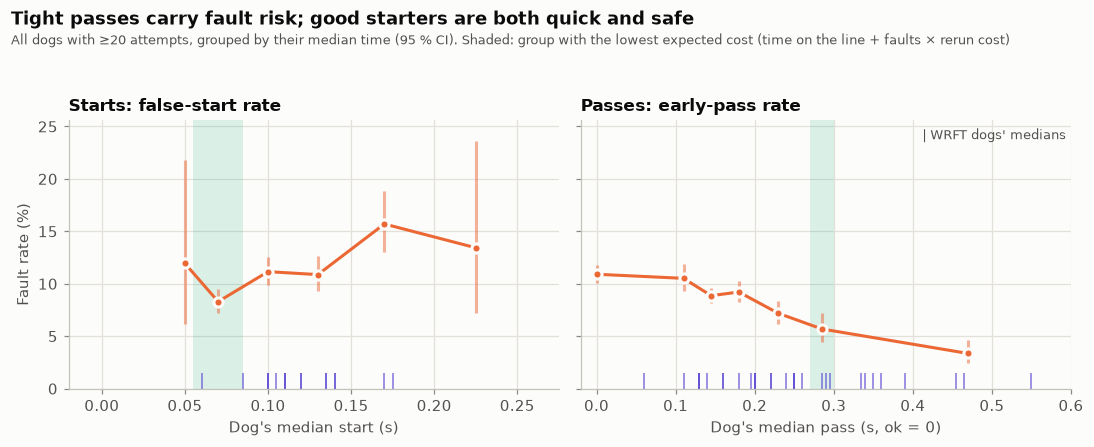

In [9]:
cost = metrics.fault_cost_seconds(heats).set_index("fault")["rerun_seconds_median"]
profiles = {k: metrics.pass_profile(runs, k) for k in ("start", "pass")}
window = pd.concat([metrics.pass_window(profiles["start"], "start", cost["false_start"]),
                    metrics.pass_window(profiles["pass"], "pass", cost["pass_fault"])], ignore_index=True)
display(window)
plots.pass_window(window, profiles)

**Reading it:**
- **Passes.** The tighter a dog passes, the more often it passes early:
  - about **11 %** for dogs whose median pass is under 0.12 s;
  - **7 %** at 0.20–0.25 s;
  - **3 %** above 0.35 s.

  Passing 0.1 s tighter saves 0.1 s per pass, but adds 1–2 points of early-pass risk, and an early pass costs 8 s or the heat. The expected cost is lowest around **0.25–0.35 s**, but the curve is fairly flat between 0.12 and 0.35 s. **Passing tighter than about 0.12 s does not pay.**
- **Starts.** Here the opposite holds: the dogs with the quickest starts (median 0.05–0.08 s) also false-start least (8 %). Starting is a skill, not a gamble. Dogs with slow, hesitant starts (median ≥ 0.14 s) false-start most (16 %).
- This is a between-dog comparison, so it shows an association, not proof that changing one dog's timing would change its fault rate.

> **For the coach:** use the most precise starter as dog 1. Passes do not need to be razor-tight: aim for about 0.15–0.30 s, not "ok".

## 5. Dogs

### 5.1 Scorecards
One row per WRFT dog (`reports/dog_scorecards.csv`):
- run speed: median, best (5th percentile) and consistency (MAD);
- start skill: median start and false-start rate at position 1;
- pass skill: median pass, `ok` share and early-pass rate at positions 2–4;
- run faults.

Every rate has a 95 % Wilson CI and an **empirical-Bayes (shrunken) value**, `*_eb`. That is the one to rank dogs by: it pulls dogs with few attempts towards the team average, so 0 faults in 5 runs does not count as "perfect". `adj_run_s` is the dog's speed from the mixed model in 5.2 (position 1, 25 cm hurdle, an average day), also shrunken.

,dog,valid_runs,median_run,adj_run_s,best_run_p05,run_mad,usual_hurdle_cm,usual_position,false_start_eb,early_pass_eb,run_fault_eb,any_fault_eb
0,Enola,189,3.960,3.944,3.874,0.040,27.5,1,0.101,0.064,0.002,0.045
1,Moon,120,3.965,3.911,3.860,0.055,27.5,2,NaN,0.131,0.003,0.078
2,Alfie,215,3.980,3.957,3.857,0.060,27.5,3,NaN,0.081,0.010,0.047
3,Maggie,226,4.030,3.998,3.920,0.050,27.5,3,0.074,0.108,0.006,0.059
4,Cookies,63,4.030,4.084,3.820,0.090,27.5,1,0.338,0.084,0.029,0.125
5,Tyna,160,4.035,4.019,3.930,0.045,27.5,4,NaN,0.083,0.008,0.048
6,Sirius,96,4.060,4.067,3.870,0.110,27.5,4,0.143,0.069,0.037,0.051
7,Sunny,118,4.070,4.074,3.940,0.065,25.0,1,0.170,NaN,0.003,0.079
8,Pax,140,4.090,4.052,3.960,0.070,25.0,2,0.104,0.097,0.003,0.054
9,Falco,113,4.140,4.118,3.950,0.090,27.5,1,0.236,0.091,0.072,0.104


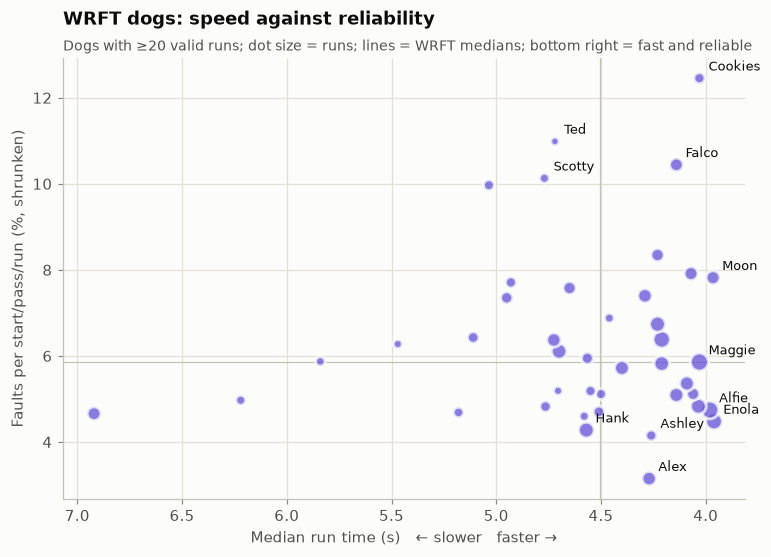

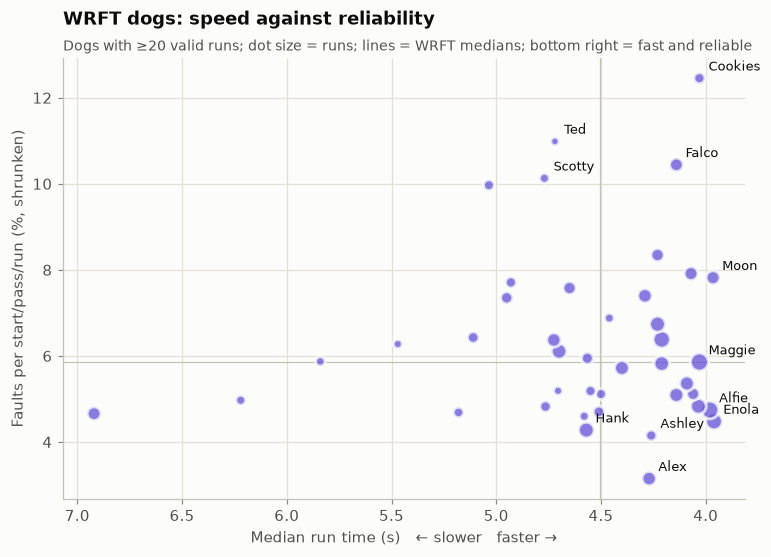

In [10]:
dog_models = {"WRFT": stats.dog_run_model(runs[runs["is_wrft_dog"]]),
              "Field": stats.dog_run_model(runs[runs["dog_key"].notna()])}
card = metrics.dog_scorecard(runs[runs["is_wrft_dog"]], dogs).merge(
    dog_models["WRFT"]["adjusted_speed"].rename_axis("dog").reset_index(), on="dog", how="left")
cols = ["dog", "valid_runs", "median_run", "adj_run_s", "best_run_p05", "run_mad", "usual_hurdle_cm",
        "usual_position", "false_start_eb", "early_pass_eb", "run_fault_eb", "any_fault_eb"]
display(card[cols])
plots.dog_quadrant(card)

**Reading it:**
- **Fast and reliable:** Enola, Alfie and Tyna (3.96–4.04 s with about 4.5–5 % faults), and Alex (4.27 s, the most reliable at 3 %).
- **Fast but faulty:** Cookies (4.03 s, 34 % false starts as a starter), Falco (24 % false starts, 7 % run faults) and Moon (13 % early passes).
- **False-start risks as dog 1** (shrunken rate): Scotty 37 %, Cookies 34 %, Riley 33 %, Negro 32 %, Bailey and Gordon 26 %.
- **Run-fault risks:** Ted 22 % and Kent 21 % (few runs, so treat with care), and Falco 7 %.
- The slowest dogs (Gordon 6.9 s, Dusty 6.2 s, Jasper 5.8 s) are the **15 cm height dogs**. Whether lowering the hurdle is worth their slower runs is a line-up question for Phase 4e.

### 5.2 Running position and hurdle height

Does a dog run faster in some positions, or over lower hurdles? Comparing raw medians would mislead, because fast dogs are put first and small dogs bring low hurdles. The mixed model compares **each dog with itself on the same day**:

`log(run time) ~ position + hurdle step + competition-day + (1 | dog)`

It is fitted on WRFT dogs and on the whole field (903 dogs), with a dog-fixed-effects model with dog-clustered errors as a robustness check.

,model,term,pct,pct_low,pct_high,seconds_at_median,p_value,group
0,mixed,C(position)[T.2],0.898,0.490,1.307,0.038,1.522e-05,WRFT
1,mixed,C(position)[T.3],0.613,0.174,1.053,0.026,6.163e-03,WRFT
2,mixed,C(position)[T.4],0.869,0.380,1.359,0.037,4.794e-04,WRFT
3,mixed,hurdle_step,0.336,0.224,0.448,0.014,4.027e-09,WRFT
4,dog_fixed_effects,C(position)[T.2],0.899,-0.106,1.913,0.038,7.977e-02,WRFT
5,dog_fixed_effects,C(position)[T.3],0.611,-0.510,1.745,0.026,2.864e-01,WRFT
6,dog_fixed_effects,C(position)[T.4],0.865,-0.608,2.360,0.037,2.511e-01,WRFT
7,dog_fixed_effects,hurdle_step,0.346,-0.042,0.736,0.015,8.076e-02,WRFT
8,mixed,C(position)[T.2],0.803,0.637,0.969,0.034,1.729e-21,Field
9,mixed,C(position)[T.3],0.781,0.608,0.954,0.033,6.872e-19,Field


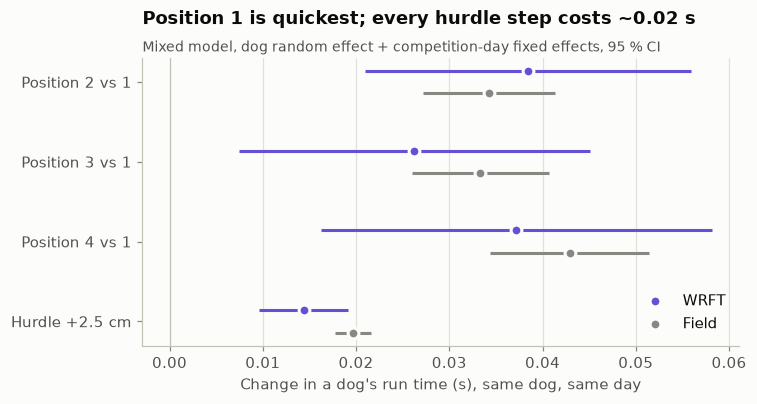

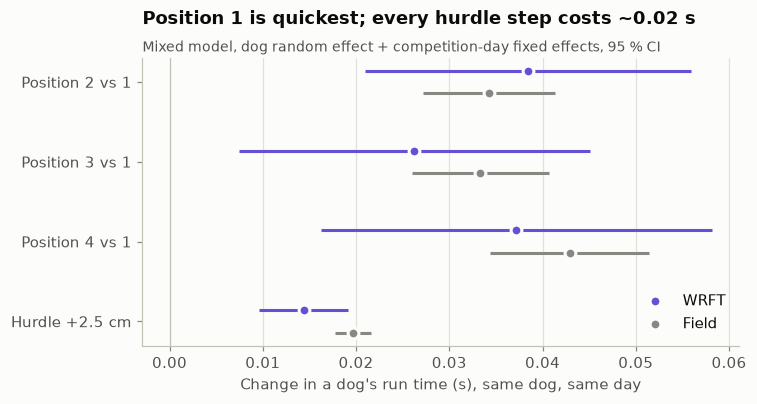

In [11]:
effects = pd.concat([m["effects"].assign(group=g) for g, m in dog_models.items()], ignore_index=True)
display(effects)
plots.dog_effects(effects)

**Reading it:**
- **Position 1 is the quickest**: the same dog runs 0.03–0.04 s (about 0.6–1 %) slower in positions 2–4. The likely reason is that the first dog starts on a free run-up, while the others start at the pass, with the returning dog in the lane.
- **Each 2.5 cm of hurdle costs about 0.02 s per dog per run** (field estimate 0.020 s, 95 % CI 0.018–0.022; WRFT 0.014 s). Going from 25 cm to 15 cm saves about 0.08 s per dog, so about 0.3 s per heat for four dogs.
- The WRFT-only fixed-effects CIs are wide (50 dogs). The whole-field estimates are precise, and the two models agree.

> **For the coach:** a height dog that lowers the hurdle by 4 steps is worth about 0.3 s per heat in hurdle savings. That only pays off if the dog itself is less than about 0.3 s slower than the dog it replaces. Gordon is about 2.6 s slower than a typical WRFT dog, so lowering the hurdle does not make up for it. This is analysed properly in Phase 4e.

## 6. Sensitivity checks

How much do the headline numbers move when an exclusion rule is switched off or changed?

In [12]:
sens = metrics.sensitivity(heats, runs)
for label, data in (("full model, without loss/loss heats", metrics.heat_model_frame(view).query("~both_lost")),):
    fit = stats.heat_win_models(data)["comparison"].set_index("model")["pseudo_r2"]
    print(f"Heat-win model, {label}: pseudo-R² speed {fit['speed']:.3f}, faults {fit['faults']:.3f}, full {fit['full']:.3f}")
sens

Heat-win model, full model, without loss/loss heats: pseudo-R² speed 0.024, faults 0.281, full 0.305


,check,baseline,variant,delta,note
0,WRFT win rate: drop WRFT-vs-WRFT heats,0.408,0.391,-1.717e-02,
1,WRFT win rate: drop ties,0.408,0.408,-1.657e-04,
2,WRFT win rate: paired heats only,0.408,0.405,-3.181e-03,
3,dog median run: keep per-dog outliers (median ...,0.000,0.000,0.000e+00,max 0.030 s
4,dog median pass: keep held passes > 3 s (media...,0.000,0.000,0.000e+00,max 4.160 s


**Reading it:** no headline depends on an exclusion choice.
- **WRFT win rate (40.8 %):**
  - dropping WRFT-vs-WRFT heats: −1.7 points;
  - dropping ties or unpaired heats: < 0.5 points.
- **Dog medians:**
  - keeping the per-dog outlier runs changes no median by more than 0.03 s;
  - keeping held passes over 3 s leaves the typical dog unchanged. One dog moves by 4 s, which is why held passes are excluded.
- **Heat-win model:** without the loss/loss heats, faults still explain far more than speed (pseudo-R² 0.28 vs 0.02).

## 7. Summary for the coach

1. **A clean heat is the strongest lever.** A fault turns a 49 % heat into a 9 % heat. Who faulted explains about 15 times more of the results than typical speed.
2. **WRFT lost 155 heats it would probably have won clean**, 23 % of all its losses. Early passes are the main cause (99), then false starts (58).
3. **False starts are a WRFT weakness:** 15.8 % of heats against 10.6 % for the field. XXL has 20 points more than its peers. The best starters are both quick and safe, so choose dog 1 for precision.
4. **Passes:** tighter than about 0.12 s does not pay; 0.15–0.30 s is the sensible target.
5. **Team fixes:** XXL the start; Hopefuls the passes; Zephyr run faults; Maximini clean heats (7.6 points below its peers). Wonders and XXL are seeded in divisions about 2 s too fast for them.
6. **Dogs:** Enola, Alfie, Tyna and Alex are the fast and reliable core. Cookies, Falco, Scotty and Riley are the main fault risks.
7. **Hurdle and position:** each hurdle step costs about 0.02 s per dog; positions 2–4 are about 0.035 s slower than position 1 for the same dog.

Next, Phase 4: lanes (Q1), passing onto male/female and intact/neutered dogs (Q2), the per-competition view (Q3), weather, and the line-up.